*Robot Motion Control · Chapter 3 — Lyapunov Stability and Model-Based Control*

# 3.1 Lyapunov Stability and Passivity

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/RMC/03-lyapunov-and-model-based-control/3.1-lyapunov-stability.ipynb)


A linear control system is stable if its poles lie in the left half-plane; a robot is not a linear system. Its
equations are nonlinear, they change with the configuration, and the controllers we wish to analyse — PD with
gravity compensation, computed torque, adaptive and sliding-mode laws — are nonlinear as well. This notebook
develops the tool that replaces the pole calculation: **Lyapunov's direct method**, which proves stability by
exhibiting an energy-like function that decreases along every trajectory, together with **LaSalle's invariance
principle** (which handles the usual case in which the function decreases only *almost* everywhere) and the
notion of **passivity**, which explains in one line why the mechanical energy of a robot is such a good
Lyapunov function. Everything is first seen on a pendulum and then checked on a real UR5e arm in MuJoCo.

| | |
|:--|:--|
| **Primary reading** | Craig, *Introduction to Robotics*, 3rd ed., Ch. 10 (nonlinear control of manipulators, including the Lyapunov-stability analysis of the control law) |
| **Parallel reading** | Slotine & Li, *Applied Nonlinear Control*, Ch. 3–4 (Lyapunov theory) · Khalil, *Nonlinear Systems*, 3rd ed., Ch. 4 (Lyapunov stability) · Spong, Hutchinson & Vidyasagar, 2nd ed., Appendix C (Lyapunov stability) · Siciliano et al., Ch. 8 (motion control) |
| **Lectures** | [Sapienza *Robotics 2* (A. De Luca), lecture playlist](https://www.youtube.com/playlist?list=PLAQopGWlIcya6LnIF83QlJTqvpYmJXnDm) · Prof. G. C. Nandi, *Mathematical Foundation of Robotics — Execution Level …* (second playlist; URL not yet verified) |
| **Prerequisites** | Linear time response and pole locations (RMC Chapter 1); manipulator dynamics $M\ddot q + C\dot q + g = \tau$ (MFoR Chapter 6); [Mathematics Primer M5 (ODEs) and M3 (eigenvalues)](../../math-primer/README.md) |
| **Study time** | about 3 hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. state the definitions of stability, asymptotic stability, exponential stability and global asymptotic stability of an equilibrium, and classify the equilibria of a pendulum from a phase portrait;
2. apply Lyapunov's **indirect method** (linearisation) and recognise the cases in which it is inconclusive;
3. use Lyapunov's **direct method**: pick a candidate $V(x)$, compute $\dot V = \nabla V\cdot f$ without solving the differential equation, and conclude stability, asymptotic stability or global asymptotic stability;
4. solve the **Lyapunov matrix equation** $A^{\mathsf T}P + PA = -Q$ and use the resulting quadratic function to estimate a **region of attraction** and a decay rate;
5. apply **LaSalle's invariance principle** when $\dot V$ is only negative semi-definite, for instance for a damped pendulum or a PD-controlled arm;
6. define **passivity**, show that the map from joint torque to joint velocity of any manipulator is passive with the mechanical energy as storage function, and verify the power balance $\dot E = \tau^{\mathsf T}\dot q$ numerically on a UR5e in MuJoCo.

## Contents

1. [Why eigenvalues are not enough](#1.-Why-eigenvalues-are-not-enough)
2. [Equilibria and the definitions of stability](#2.-Equilibria-and-the-definitions-of-stability)
3. [The pendulum: phase portraits and energy level sets](#3.-The-pendulum:-phase-portraits-and-energy-level-sets)
4. [Linearisation: Lyapunov's indirect method](#4.-Linearisation:-Lyapunov's-indirect-method)
5. [Lyapunov's direct method](#5.-Lyapunov's-direct-method)
6. [Linear systems and the Lyapunov equation](#6.-Linear-systems-and-the-Lyapunov-equation)
7. [Estimating the region of attraction](#7.-Estimating-the-region-of-attraction)
8. [LaSalle's invariance principle](#8.-LaSalle's-invariance-principle)
9. [Passivity and the energy of a manipulator](#9.-Passivity-and-the-energy-of-a-manipulator)
10. [A real robot: the power balance of a UR5e in MuJoCo](#10.-A-real-robot:-the-power-balance-of-a-UR5e-in-MuJoCo)
11. [Worked examples](#11.-Worked-examples)
12. [Summary, common mistakes and exercises](#12.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import lyapunov as ly
from rgkit import model_based_control as mbc
from scipy.linalg import expm
from scipy.integrate import trapezoid as trap

## 1. Why eigenvalues are not enough

For a linear time-invariant system $\dot x = Ax$ stability is decided by the eigenvalues of $A$: if every
eigenvalue has a negative real part then every solution decays, and the question is closed. A manipulator
obeys instead

$$
M(q)\,\ddot q + C(q,\dot q)\,\dot q + g(q) = \tau ,
$$

whose coefficients depend on the state. Three difficulties follow.

* **There is no global "pole".** Linearising about one configuration gives a different linear system in
  every configuration, and the linearisation says nothing about large motions.
* **Several equilibria may coexist.** A pendulum hanging down and a pendulum balanced upright are both at rest;
  one is stable and the other is not, and a linear model of the whole system cannot even express this.
* **The controller is nonlinear too.** Computed torque, adaptive and sliding-mode controllers contain products
  of state-dependent matrices and the state itself.

Aleksandr Lyapunov's idea (1892) is to bypass the solution of the differential equation altogether. If we can
find a scalar function $V(x)$ that behaves like an **energy** — positive away from the equilibrium and
strictly decreasing along trajectories — then the state can only move "downhill" towards the equilibrium. We
need to *evaluate* $\dot V$ along the vector field, never to *integrate* the equations of motion. For
mechanical systems nature supplies the candidate: the total mechanical energy.

Throughout this notebook we use the **normalised pendulum** (time measured in units of $\sqrt{\ell/g}$)

$$
\ddot\theta = -\sin\theta - b\,\dot\theta ,\qquad x = \begin{bmatrix}\theta\\ \omega\end{bmatrix},\ \omega = \dot\theta,\qquad
\dot x = f(x) = \begin{bmatrix}\omega\\ -\sin\theta - b\,\omega\end{bmatrix},
$$

where $\theta = 0$ is the *hanging* position and $b\ge 0$ is a viscous damping coefficient. Its energy
(per unit $m\ell^2$) is $E(x) = \tfrac12\omega^2 + 1 - \cos\theta$, which is zero at the hanging equilibrium.

## 2. Equilibria and the definitions of stability

Consider an **autonomous** system $\dot x = f(x)$ with $f$ locally Lipschitz, so that solutions exist and are
unique. A point $x^\ast$ is an **equilibrium** if $f(x^\ast) = 0$; by the change of variable $x \to x - x^\ast$
we may and shall assume $x^\ast = 0$. Write $\lVert\cdot\rVert$ for the Euclidean norm.

> **Definition (stability in the sense of Lyapunov).** The equilibrium $x=0$ is
>
> * **stable** if for every $\varepsilon>0$ there is $\delta(\varepsilon)>0$ such that $\lVert x(0)\rVert<\delta \Rightarrow \lVert x(t)\rVert<\varepsilon$ for all $t\ge 0$;
> * **unstable** if it is not stable;
> * **asymptotically stable** if it is stable and there is $\delta'>0$ with $\lVert x(0)\rVert<\delta' \Rightarrow x(t)\to 0$;
> * **exponentially stable** if there are $k,\lambda>0$ with $\lVert x(t)\rVert\le k\,\lVert x(0)\rVert e^{-\lambda t}$ near the origin;
> * **globally asymptotically stable (GAS)** if it is asymptotically stable and every solution converges to $0$.
>
> The set of initial states from which solutions converge to $0$ is the **region of attraction**.

Stability is a statement about *staying close*, asymptotic stability adds *coming back*. A frictionless
pendulum oscillating about the hanging position is stable but not asymptotically stable: small oscillations stay
small, yet they never die out. A pendulum balanced upright is unstable: an arbitrarily small push sends it
far away. For robot control we almost always want **asymptotic** stability, usually with a known region of
attraction, ideally the whole state space.

Notice that exponential stability is stronger than asymptotic stability: the scalar system $\dot x = -x^3$ is
asymptotically stable but converges only like $1/\sqrt{t}$ (Section 11), so no exponential bound exists.

## 3. The pendulum: phase portraits and energy level sets

The **phase portrait** draws the solutions in the $(\theta,\omega)$ plane. The curves $E(x)=c$ are the **level
sets** (contours) of the energy. For the frictionless pendulum $\dot E = \omega\dot\omega + \sin\theta\,\omega
= -\omega\sin\theta+\omega\sin\theta = 0$: energy is conserved, so each trajectory *is* a level set of $E$.
With damping, $\dot E = \omega\dot\omega + \sin\theta\,\omega = -b\,\omega^2 \le 0$, and trajectories cut
through the level sets from the outside to the inside. The red curve $E = 2$ passes through the unstable
upright equilibria $(\pm\pi, 0)$: it separates *oscillation* (inside) from *rotation* (outside).

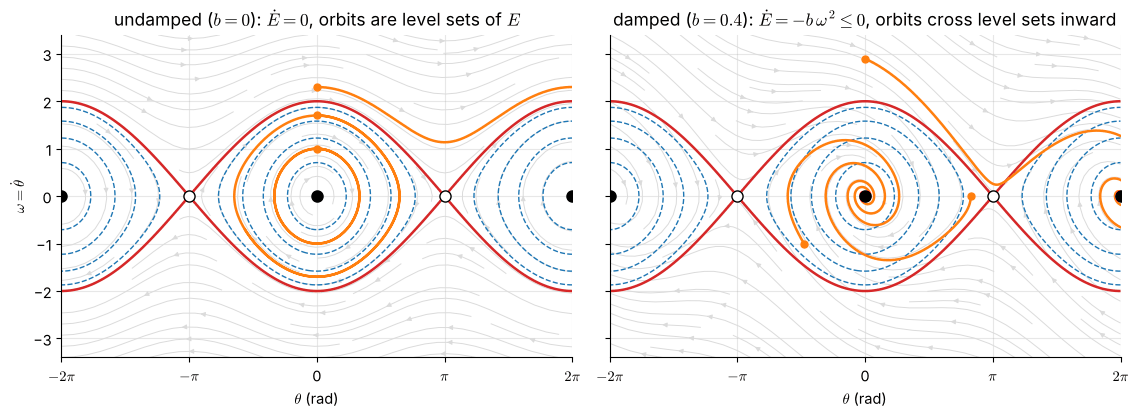

Black dots: stable equilibria (hanging). White dots: unstable equilibria (upright). Red: E = 2 (separatrix). Blue dashed: E = 0.25 ... 1.75.
Right panel: the two orbits started inside E < 2 spiral into the hanging equilibrium; the one started above the separatrix first rotates and is captured by the neighbouring well.


In [2]:
wn2 = 1.0
TH, OM = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 241), np.linspace(-3.4, 3.4, 161))
Egrid = ly.pendulum_energy(np.stack([TH, OM], -1))

def portrait(ax, b, starts, T=40.0):
    f = ly.pendulum_field(1.0, b)
    ax.streamplot(TH, OM, OM, -np.sin(TH) - b * OM, color="0.86", density=1.0, linewidth=0.7, arrowsize=0.7)
    ax.contour(TH, OM, Egrid, levels=[0.25, 0.75, 1.25, 1.75], colors="tab:blue", linewidths=1.0, linestyles="--")
    ax.contour(TH, OM, Egrid, levels=[2.0], colors="tab:red", linewidths=1.8)
    for x0 in starts:
        tr = ly.rk4_trajectory(f, x0, np.linspace(0, T, 4001))
        ax.plot(tr[:, 0], tr[:, 1], color="tab:orange", lw=1.8)
        ax.plot(*x0, "o", color="tab:orange", ms=5)
    for k in range(-2, 3):
        ax.plot(k * np.pi, 0, "o", ms=8, mfc="white" if k % 2 else "k", mec="k", zorder=5)
    ax.set_xlim(-2 * np.pi, 2 * np.pi); ax.set_ylim(-3.4, 3.4)
    ax.set_xticks(np.pi * np.arange(-2, 3)); ax.set_xticklabels([r"$-2\pi$", r"$-\pi$", "0", r"$\pi$", r"$2\pi$"])
    ax.set_xlabel(r"$\theta$ (rad)"); ax.set_ylabel(r"$\omega=\dot\theta$")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), sharey=True)
portrait(axes[0], 0.0, [(0.0, 1.0), (0.0, 1.7), (0.0, 2.3)], T=14)
axes[0].set_title(r"undamped ($b=0$): $\dot E=0$, orbits are level sets of $E$")
portrait(axes[1], 0.4, [(2.6, 0.0), (-1.5, -1.0), (0.0, 2.9)])
axes[1].set_title(r"damped ($b=0.4$): $\dot E=-b\,\omega^2\leq 0$, orbits cross level sets inward")
axes[1].set_ylabel("")
plt.tight_layout(); plt.show()
print("Black dots: stable equilibria (hanging). White dots: unstable equilibria (upright). Red: E = 2 (separatrix). Blue dashed: E = 0.25 ... 1.75.")
print("Right panel: the two orbits started inside E < 2 spiral into the hanging equilibrium; the one started above the separatrix first rotates and is captured by the neighbouring well.")

## 4. Linearisation: Lyapunov's indirect method

Near an equilibrium $x^\ast$ the nonlinear system behaves like its linearisation
$\dot z = Az$ with $A = \partial f/\partial x\,\big|_{x^\ast}$ and $z = x - x^\ast$.

> **Theorem (Lyapunov's indirect method).** Let $A$ be the Jacobian of $f$ at the equilibrium.
> 1. If every eigenvalue of $A$ has negative real part, the equilibrium is (locally) **exponentially stable**.
> 2. If at least one eigenvalue has positive real part, the equilibrium is **unstable**.
> 3. If no eigenvalue has positive real part but some have zero real part, the linearisation is **inconclusive**.

Case 3 is not a technicality. It is the situation of the undamped pendulum (eigenvalues $\pm i$) and, more
importantly, of almost every robot controller that has no integrator or no damping in some direction. The
table computes the Jacobian numerically at the two kinds of pendulum equilibria.

In [3]:
rows = []
for b in (0.0, 0.4):
    f = ly.pendulum_field(1.0, b)
    for name, xe in (("hanging (0, 0)", [0.0, 0.0]), ("upright (π, 0)", [np.pi, 0.0])):
        lam = np.linalg.eigvals(ly.numerical_jacobian(f, xe))
        lam = lam[np.argsort(lam.real)]
        s = ",  ".join(f"{l.real:+.3f}{l.imag:+.3f}i" if abs(l.imag) > 1e-9 else f"{l.real:+.3f}" for l in lam)
        verdict = ("unstable (saddle)" if lam.real.max() > 1e-9 else
                   "locally exponentially stable" if lam.real.max() < -1e-9 else "inconclusive")
        rows.append(f"| {b} | {name} | {s} | {verdict} |")
display(Markdown("| damping b | equilibrium | eigenvalues of A | indirect method |\n|:--|:--|:--|:--|\n" + "\n".join(rows)))

| damping b | equilibrium | eigenvalues of A | indirect method |
|:--|:--|:--|:--|
| 0.0 | hanging (0, 0) | +0.000+1.000i,  -0.000-1.000i | inconclusive |
| 0.0 | upright (π, 0) | -1.000,  +1.000 | unstable (saddle) |
| 0.4 | hanging (0, 0) | -0.200+0.980i,  -0.200-0.980i | locally exponentially stable |
| 0.4 | upright (π, 0) | -1.220,  +0.820 | unstable (saddle) |

The hanging equilibrium of the damped pendulum is a stable focus (complex eigenvalues with real part
$-b/2$): locally exponentially stable. The upright one is a saddle (one positive eigenvalue): unstable. For
the undamped pendulum the hanging equilibrium has eigenvalues $\pm i$ and the indirect method is silent —
yet the phase portrait shows closed orbits, i.e. stability.

**The linearisation can also be silent about the *kind* of stability.** The scalar systems $\dot x=-x^3$ and
$\dot x=+x^3$ both have the linearisation $\dot z = 0$, yet the first is asymptotically stable and the second
unstable. Their exact solutions with $x(0)=x_0$ are $x(t) = x_0/\sqrt{1+2x_0^2t}$ (decay, but only
algebraically) and $x(t) = x_0/\sqrt{1-2x_0^2t}$ (which **escapes to infinity in finite time** $1/(2x_0^2)$).

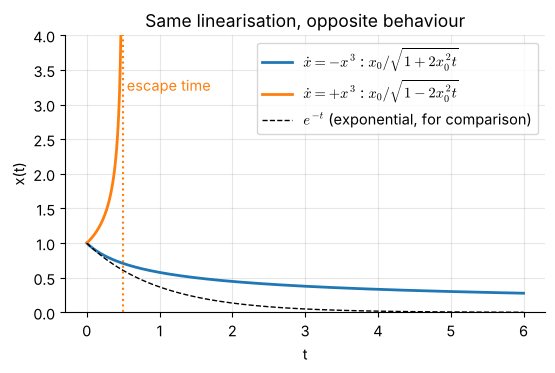

xdot = -1 x^3: RK4 x(0.4) = 0.745356, closed form 0.745356
xdot = +1 x^3: RK4 x(0.4) = 2.236068, closed form 2.236068


In [4]:
t = np.linspace(0, 6, 601)
x0 = 1.0
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(t, x0 / np.sqrt(1 + 2 * x0**2 * t), lw=2, label=r"$\dot x=-x^3$ : $x_0/\sqrt{1+2x_0^2t}$")
t_esc = 1 / (2 * x0**2)
tt = t[t < t_esc * 0.995]
ax.plot(tt, x0 / np.sqrt(1 - 2 * x0**2 * tt), lw=2, label=r"$\dot x=+x^3$ : $x_0/\sqrt{1-2x_0^2t}$")
ax.plot(t, x0 * np.exp(-t), "k--", lw=1, label=r"$e^{-t}$ (exponential, for comparison)")
ax.axvline(t_esc, color="tab:orange", ls=":"); ax.text(t_esc + 0.05, 3.2, "escape time", color="tab:orange")
ax.set_ylim(0, 4); ax.set_xlabel("t"); ax.set_ylabel("x(t)"); ax.legend(); ax.set_title("Same linearisation, opposite behaviour")
plt.show()
# numerical confirmation of the closed forms (RK4)
for sign in (-1, +1):
    tr = ly.rk4_trajectory(lambda x: sign * x**3, [x0], np.linspace(0, 0.4, 4001))
    exact = x0 / np.sqrt(1 - sign * 2 * x0**2 * 0.4)
    print(f"xdot = {sign:+d} x^3: RK4 x(0.4) = {tr[-1, 0]:.6f}, closed form {exact:.6f}")

## 5. Lyapunov's direct method

The direct method asks for a scalar function with three properties.

> **Theorem (Lyapunov).** Let $x=0$ be an equilibrium of $\dot x=f(x)$ and let $D\subset\mathbb R^n$ be a
> neighbourhood of $0$. Let $V:D\to\mathbb R$ be continuously differentiable with $V(0)=0$ and $V(x)>0$ for
> $x\ne 0$ (*positive definite*). Define the **derivative along trajectories**
> $$\dot V(x) = \frac{\partial V}{\partial x}f(x) = \nabla V(x)^{\mathsf T}f(x).$$
> 1. If $\dot V(x)\le 0$ in $D$, the origin is **stable**.
> 2. If $\dot V(x)<0$ in $D\setminus\{0\}$, the origin is **asymptotically stable**.
> 3. If $D=\mathbb R^n$, $V$ is **radially unbounded** ($V(x)\to\infty$ as $\lVert x\rVert\to\infty$) and $\dot V(x)<0$ for $x\ne 0$, the origin is **globally asymptotically stable**.

*Why it works (sketch).* Choose $\varepsilon$ so that the ball $B_\varepsilon\subset D$ and let $c$ be the minimum of
$V$ on its boundary sphere; $c>0$ because $V$ is positive definite. By continuity there is $\delta>0$ with
$V<c$ on $B_\delta$. A trajectory starting in $B_\delta$ has $V(x(0))<c$, and since $V$ never increases it can
never reach the sphere where $V\ge c$; hence it stays in $B_\varepsilon$ — stability. If in addition $V$
strictly decreases, $V(x(t))$ is a decreasing function bounded below, so it converges to some $V_\infty\ge0$;
if $V_\infty>0$ the trajectory would stay in a compact region away from the origin where $\dot V\le -\gamma<0$,
and $V$ would reach negative values — a contradiction. Hence $V\to0$ and $x\to0$. Radial unboundedness makes
every sublevel set $\{V\le c\}$ bounded, so the argument works from any starting point.

Three remarks make the theorem easy to use.

* $\dot V$ is computed from $f$ alone, by the chain rule: **no solution of the ODE is needed**.
* Geometrically $\dot V<0$ says that the vector field points *into* the level set of $V$ through each point
  ($\nabla V\cdot f<0$): the level sets are one-way barriers. This is what the damped panel of the figure above shows.
* The conditions are **sufficient**. If a candidate fails, nothing is proved; another candidate may still work.
  Finding $V$ is the art of the method — and the reason why mechanical energy, which comes for free, is so valuable.

**Example: the damped pendulum.** With $V = E = \tfrac12\omega^2 + 1-\cos\theta$ we found $\dot E = -b\omega^2\le0$ on
all of $\mathbb R^2$. Because $E$ is positive definite on the set $|\theta|<2\pi$ (a neighbourhood of the origin), the origin is stable.
But $\dot E$ is only *negative semi-definite* (it vanishes whenever $\omega=0$, wherever the pendulum is), so
the theorem does not yet prove asymptotic stability. Section 8 closes the gap.

## 6. Linear systems and the Lyapunov equation

For $\dot x = Ax$ the natural candidate is a **quadratic form** $V(x)=x^{\mathsf T}Px$ with $P=P^{\mathsf T}>0$. Then

$$
\dot V = \dot x^{\mathsf T}Px + x^{\mathsf T}P\dot x = x^{\mathsf T}\!\left(A^{\mathsf T}P+PA\right)x \;=:\; -\,x^{\mathsf T}Qx .
$$

> **Theorem (Lyapunov equation).** $A$ is Hurwitz (all eigenvalues in the open left half-plane) if and only if
> for some — equivalently every — symmetric $Q>0$ the equation
> $$A^{\mathsf T}P + PA = -Q$$
> has a unique solution $P$, and that $P$ is symmetric positive definite. It is given by
> $P=\int_0^\infty e^{A^{\mathsf T}t}Q\,e^{At}\,dt$.

Since $x^{\mathsf T}Qx \ge \lambda_{\min}(Q)\lVert x\rVert^2 \ge \dfrac{\lambda_{\min}(Q)}{\lambda_{\max}(P)}\,x^{\mathsf T}Px$, we obtain the
**decay estimate** $\dot V\le -\rho V$ with $\rho = \lambda_{\min}(Q)/\lambda_{\max}(P)$, hence
$V(x(t))\le V(x(0))e^{-\rho t}$: a *certified* exponential rate, without computing any eigenvalue of $A$.
The cell below solves the equation for the linearised damped pendulum and checks the certificate against the
exact linear solution $x(t)=e^{At}x_0$.

In [5]:
b = 0.4
A = ly.numerical_jacobian(ly.pendulum_field(1.0, b), [0.0, 0.0]).round(12)
Q = np.eye(2)
P = ly.solve_lyapunov(A, Q)
display(Math(matrix_to_latex(A, 3, "A") + r",\quad " + matrix_to_latex(P, 3, "P")))
print("A'P + PA = -Q :", np.allclose(A.T @ P + P @ A, -Q), "    P positive definite :", ly.is_positive_definite(P))
rho = np.linalg.eigvalsh(Q).min() / np.linalg.eigvalsh(P).max()
print(f"certified decay rate rho = lambda_min(Q)/lambda_max(P) = {rho:.4f}   (true rate of V: 2*|Re lambda| = {-2*np.linalg.eigvals(A).real.max():.4f})")

x0 = np.array([0.8, -0.5])
ts = np.linspace(0, 12, 241)
V_t = np.array([(expm(A * t) @ x0) @ P @ (expm(A * t) @ x0) for t in ts])
print("V(t) <= V(0) exp(-rho t) for all t :", bool(np.all(V_t <= V_t[0] * np.exp(-rho * ts) + 1e-12)))

<IPython.core.display.Math object>

A'P + PA = -Q : True     P positive definite : True
certified decay rate rho = lambda_min(Q)/lambda_max(P) = 0.3216   (true rate of V: 2*|Re lambda| = 0.4000)
V(t) <= V(0) exp(-rho t) for all t : True


## 7. Estimating the region of attraction

A quadratic $V$ built for the *linearisation* is a legitimate Lyapunov function for the *nonlinear* system as
long as we stay close enough to the origin. How close? The recipe is mechanical:

1. choose $V$ (here $x^{\mathsf T}Px$ from the Lyapunov equation);
2. compute $\dot V = \nabla V\cdot f$ for the **nonlinear** $f$;
3. find the largest level $c^\ast$ such that $\dot V<0$ everywhere in $\{V<c^\ast\}$ except at the origin.

The sublevel set $\Omega_{c^\ast}=\{V<c^\ast\}$ is then *positively invariant* (trajectories cannot leave it, because
$V$ decreases) and every trajectory in it converges to the origin: $\Omega_{c^\ast}$ is an **estimate** of the
region of attraction. It is conservative — the true region is larger — and a different $V$ gives a different
estimate. For the damped pendulum we can compare three things: the true basin (found by simulating many initial
states), the estimate from the quadratic $V$, and the estimate from the energy $E$, for which LaSalle's
principle (next section) shows that $\{E<2\}$ lies in the basin.

largest certified level c* = 9.215  (V at the saddle (π,0) is 26.648)
area of {x'Px < c*} = 11.36,  area of {E < 2, |θ|<π} = 16.00


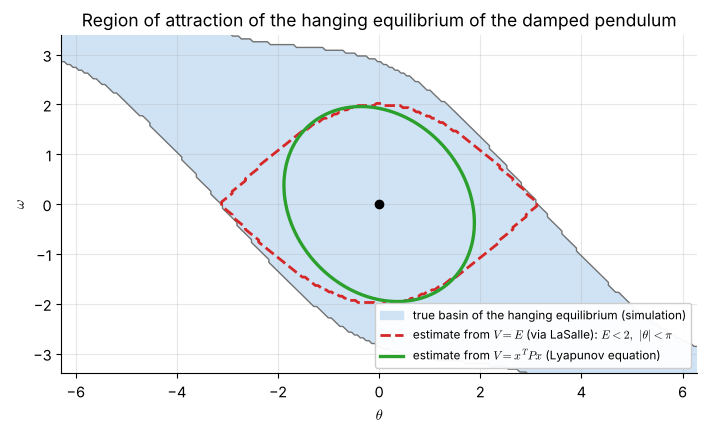

all 400 boundary points of the estimate converge to the origin: True


In [6]:
b = 0.4
f2 = lambda x, y: (y, -np.sin(x) - b * y)
Vq = lambda x, y: P[0, 0] * x**2 + 2 * P[0, 1] * x * y + P[1, 1] * y**2
gVq = lambda x, y: (2 * (P[0, 0] * x + P[0, 1] * y), 2 * (P[0, 1] * x + P[1, 1] * y))
Xg, Yg = np.meshgrid(np.linspace(-4, 4, 801), np.linspace(-4, 4, 801))
Vg, Vdg = ly.vdot_on_grid(f2, Vq, gVq, Xg, Yg)
c_star = ly.level_set_estimate(Vg, Vdg, Xg, Yg)
cell = (Xg[0, 1] - Xg[0, 0]) * (Yg[1, 0] - Yg[0, 0])
area_quad = (Vg < c_star).sum() * cell
area_energy = ((ly.pendulum_energy(np.stack([Xg, Yg], -1)) < 2.0) & (np.abs(Xg) < np.pi)).sum() * cell
print(f"largest certified level c* = {c_star:.3f}  (V at the saddle (π,0) is {Vq(np.pi, 0):.3f})")
print(f"area of {{x'Px < c*}} = {area_quad:.2f},  area of {{E < 2, |θ|<π}} = {area_energy:.2f}")

# true basin of attraction: simulate a grid of initial conditions and see which equilibrium (2πk, 0) they reach
th0, om0 = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 220), np.linspace(-3.4, 3.4, 120))
X0 = np.stack([th0.ravel(), om0.ravel()], -1)
XT = ly.rk4_batch(ly.pendulum_field(1.0, b), X0, T=60.0, n_steps=3000)
k_end = np.rint(XT[:, 0] / (2 * np.pi)).reshape(th0.shape)          # which hanging equilibrium 2πk was reached
fig, ax = plt.subplots(figsize=(8.2, 4.4))
basin0 = (k_end == 0)
ax.contourf(th0, om0, basin0.astype(float), levels=[0.5, 1.5], colors=["#cfe3f5"])
ax.contour(th0, om0, basin0.astype(float), levels=[0.5], colors="0.45", linewidths=1.0)
central = ((ly.pendulum_energy(np.stack([TH, OM], -1)) < 2.0) & (np.abs(TH) < np.pi)).astype(float)
ax.contour(TH, OM, central, levels=[0.5], colors="tab:red", linewidths=2.0, linestyles="--")
ax.contour(Xg, Yg, Vg, levels=[c_star], colors="tab:green", linewidths=2.4)
ax.plot([0], [0], "ko")
ax.fill_between([], [], [], color="#cfe3f5", label="true basin of the hanging equilibrium (simulation)")
ax.plot([], [], color="tab:red", lw=2.0, ls="--", label=r"estimate from $V=E$ (via LaSalle): $E<2,\ |\theta|<\pi$")
ax.plot([], [], color="tab:green", lw=2.4, label=r"estimate from $V=x^{T}Px$ (Lyapunov equation)")
ax.set_xlim(-2 * np.pi, 2 * np.pi); ax.set_ylim(-3.4, 3.4); ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$\omega$")
ax.set_title("Region of attraction of the hanging equilibrium of the damped pendulum")
ax.legend(loc="lower right", fontsize=8.5, framealpha=0.95); plt.show()

# verification: every point on the boundary of the quadratic estimate (slightly shrunk) converges to the origin
ang = np.linspace(0, 2 * np.pi, 400, endpoint=False)
L = np.linalg.cholesky(P)                      # x'Px = |L' x|^2
ring = np.linalg.solve(L.T, 0.995 * np.sqrt(c_star) * np.stack([np.cos(ang), np.sin(ang)]))
end = ly.rk4_batch(ly.pendulum_field(1.0, b), ring.T, T=80.0, n_steps=4000)
print("all 400 boundary points of the estimate converge to the origin:", bool(np.all(np.linalg.norm(end, axis=1) < 1e-3)))

The green quadratic estimate is a modest ellipse inside the true basin; the energy-based estimate (red) is
larger and touches the upright saddles — the best any sublevel set of $E$ can do, because $E=2$ is exactly the energy
of the saddles. The true basin (light blue, bounded by the spiral arms that are the stable manifolds of the
saddles) is larger still: a trajectory can be started with enough energy to go over the top once or twice and
still be captured by the hanging well.

> **Practical lesson.** A certified region of attraction is only as good as the Lyapunov function. For
> robot controllers the physical energy-based functions of the next notebooks give *global* results,
> which is why they are preferred to quadratic functions of the error.

## 8. LaSalle's invariance principle

We have seen the typical situation: $\dot V\le0$ but not $<0$. In the pendulum $\dot E=-b\omega^2$ vanishes
along the whole line $\omega=0$, yet the pendulum certainly does not stay there unless it is at an equilibrium. LaSalle's principle makes this
argument rigorous. A set $S$ is **invariant** if a trajectory that starts in $S$ stays in $S$ for all time.

> **Theorem (LaSalle's invariance principle).** Let $\Omega$ be a compact set that is positively invariant for $\dot x=f(x)$, and let
> $V:\Omega\to\mathbb R$ be $C^1$ with $\dot V\le 0$ on $\Omega$. Let $\mathcal E=\{x\in\Omega:\dot V(x)=0\}$ and let $\mathcal M$ be the
> **largest invariant set contained in $\mathcal E$**. Then every solution starting in $\Omega$ converges to $\mathcal M$ as $t\to\infty$.
>
> **Corollary (Barbashin–Krasovskii).** If $V$ is positive definite, $\dot V\le0$ in a neighbourhood of the origin and
> no solution other than $x(t)\equiv0$ stays identically in $\{\dot V=0\}$, the origin is asymptotically stable;
> if, moreover, $D=\mathbb R^n$ and $V$ is radially unbounded, it is globally asymptotically stable.

*Recipe.* (i) Compute $\dot V$ and the set $\mathcal E$ where it vanishes. (ii) Ask: *what must a solution that
remains in $\mathcal E$ for all time satisfy?* Substitute "stays in $\mathcal E$" into the differential equation
and solve. (iii) The solutions that survive form $\mathcal M$.

**Pendulum.** $\mathcal E=\{\omega=0\}$. A solution with $\omega\equiv0$ has $\dot\omega\equiv0$, so
$0=\dot\omega=-\sin\theta-b\cdot0$, i.e. $\sin\theta=0$ and $\theta\in\{k\pi\}$. In the compact positively invariant set
$\Omega=\{E\le c\}$ with $c<2$ (component containing the origin, which lies in $|\theta|<\pi$) the only such point is the origin. Hence
$\mathcal M=\{0\}$ and **every trajectory with $E(x(0))<2$ converges to the hanging equilibrium** — the red
estimate above. The animation shows one trajectory: the state spirals inward while $E(t)$ decreases
monotonically, with flat spots exactly where $\omega=0$ (turning points).

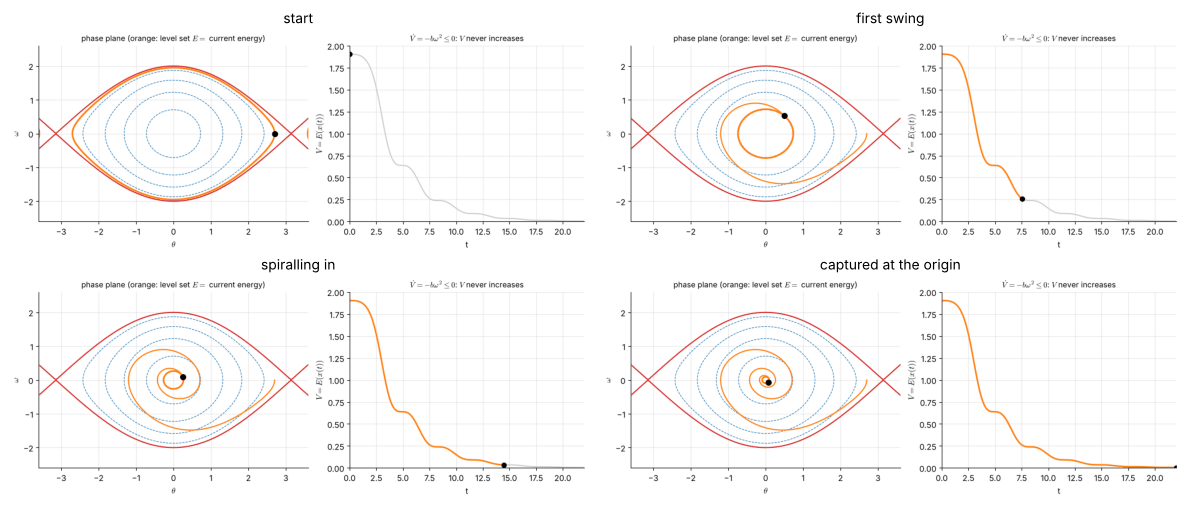

E is non-increasing along the whole trajectory: True    E(0) = 1.9041,  E(T) = 4.70e-03


In [7]:
b = 0.3
tr_t = np.linspace(0, 22, 881)
tr = ly.rk4_trajectory(ly.pendulum_field(1.0, b), [2.7, 0.0], tr_t)
E_t = ly.pendulum_energy(tr)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4.0), gridspec_kw=dict(width_ratios=[1.15, 1]), constrained_layout=True)

def update(i):
    i = int(i)
    a1.cla(); a2.cla()
    a1.contour(TH, OM, Egrid, levels=[0.25, 0.75, 1.25, 1.75], colors="tab:blue", linewidths=0.8, linestyles="--")
    a1.contour(TH, OM, Egrid, levels=[2.0], colors="tab:red", linewidths=1.5)
    a1.contour(TH, OM, Egrid, levels=[E_t[i]], colors="tab:orange", linewidths=2.2)
    a1.plot(tr[:i + 1, 0], tr[:i + 1, 1], color="tab:orange", lw=1.5); a1.plot(*tr[i], "o", color="k", ms=7)
    a1.set_xlim(-3.6, 3.6); a1.set_ylim(-2.6, 2.6); a1.set_xlabel(r"$\theta$"); a1.set_ylabel(r"$\omega$")
    a1.set_title(r"phase plane (orange: level set $E=$ current energy)", fontsize=10)
    a2.plot(tr_t, E_t, color="0.8"); a2.plot(tr_t[:i + 1], E_t[:i + 1], color="tab:orange", lw=2)
    a2.plot(tr_t[i], E_t[i], "ko"); a2.set_xlim(0, tr_t[-1]); a2.set_ylim(0, 2.0)
    a2.set_xlabel("t"); a2.set_ylabel(r"$V=E(x(t))$"); a2.set_title(r"$\dot V=-b\omega^2\leq0$: $V$ never increases", fontsize=10)

animate(fig, update, np.linspace(0, len(tr_t) - 1, 36), interval=120, gif="assets/3.1-pendulum-lasalle.gif",
        keyframe_titles=["start", "first swing", "spiralling in", "captured at the origin"])
print("E is non-increasing along the whole trajectory:", bool(np.all(np.diff(E_t) <= 1e-12)),
      "   E(0) = %.4f,  E(T) = %.2e" % (E_t[0], E_t[-1]))

**Interactive explorer.** Change the damping $b$ and the starting angle. For $b=0$ the energy stays constant (no
convergence, but stability); for any $b>0$ the energy tends to zero; for large $b$ the pendulum is
over-damped and approaches the origin without oscillating. Starting with $E>2$ (large initial velocity) the pendulum
rotates a few times first and is then captured.

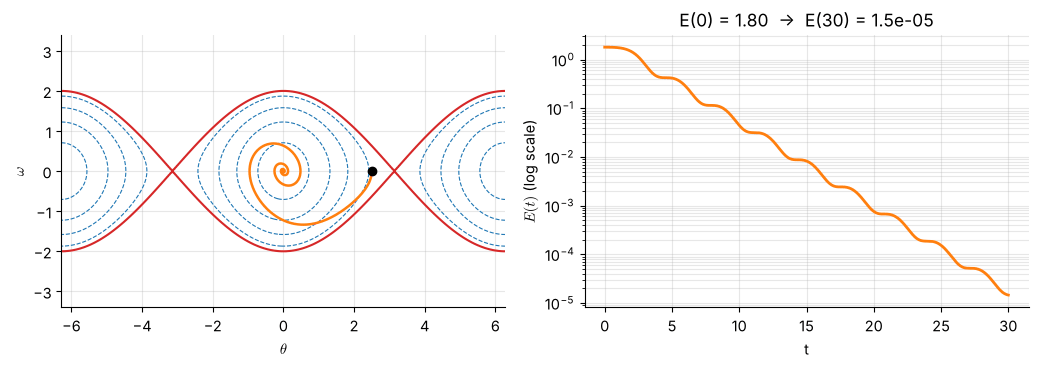

In [8]:
def explore(b=0.4, theta0=2.5, omega0=0.0):
    tt = np.linspace(0, 30, 3001)
    tr = ly.rk4_trajectory(ly.pendulum_field(1.0, b), [theta0, omega0], tt)
    E = ly.pendulum_energy(tr)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
    a1.contour(TH, OM, Egrid, levels=[0.25, 0.75, 1.25, 1.75], colors="tab:blue", linewidths=0.8, linestyles="--")
    a1.contour(TH, OM, Egrid, levels=[2.0], colors="tab:red", linewidths=1.5)
    a1.plot(tr[:, 0], tr[:, 1], color="tab:orange", lw=1.8); a1.plot(theta0, omega0, "ko")
    a1.set_xlim(-2 * np.pi, 2 * np.pi); a1.set_ylim(-3.4, 3.4); a1.set_xlabel(r"$\theta$"); a1.set_ylabel(r"$\omega$")
    a2.semilogy(tt, np.maximum(E, 1e-12), color="tab:orange", lw=2); a2.set_xlabel("t"); a2.set_ylabel(r"$E(t)$ (log scale)")
    a2.set_title(f"E(0) = {E[0]:.2f}  →  E(30) = {E[-1]:.1e}"); a2.grid(alpha=0.3, which="both")
    plt.tight_layout(); plt.show()

interact(explore, b=widgets.FloatSlider(value=0.4, min=0.0, max=2.0, step=0.05, description="damping b"),
         theta0=widgets.FloatSlider(value=2.5, min=-3.0, max=3.0, step=0.1, description="θ₀"),
         omega0=widgets.FloatSlider(value=0.0, min=-3.0, max=3.0, step=0.1, description="ω₀"))

## 9. Passivity and the energy of a manipulator

The pendulum's good behaviour came from its energy balance. **Passivity** turns that observation into a
property of an input–output map, which can then be composed with other maps (a controller, a human, an environment).

> **Definition (passivity).** A system $\dot x=f(x,u)$, $y=h(x,u)$ with $u,y\in\mathbb R^m$ is **passive** if there is a $C^1$ *storage function*
> $S(x)\ge0$ such that $\dot S\le u^{\mathsf T}y$ along every trajectory. It is **strictly (output) passive** if
> $\dot S\le u^{\mathsf T}y-\varphi(y)$ with $y^{\mathsf T}\varphi(y)>0$ for $y\ne0$.
> Integrated: $\displaystyle\int_0^T u^{\mathsf T}y\,dt \ge S(x(T))-S(x(0)) \ge -S(x(0))$ — the energy a passive system can *give back* is bounded by what it stored.

With input $u$ a force and output $y$ the velocity, $u^{\mathsf T}y$ is the **power** delivered to the system. A mass,
a spring, a damper are passive (the storage function is the kinetic energy, the elastic energy, and zero). Passive
systems connected in parallel or in feedback give a passive system; this is the fact that makes energy-based
controller design, impedance control (Chapter 5) and teleoperation (Chapter 6) so robust.

### A manipulator is passive from torque to velocity

Let $E=T+U=\tfrac12\dot q^{\mathsf T}M(q)\dot q+U(q)$ with $g(q)=\partial U/\partial q$. Differentiate:

$$
\dot E = \dot q^{\mathsf T}M\ddot q + \tfrac12\dot q^{\mathsf T}\dot M\dot q + g^{\mathsf T}\dot q .
$$

Substitute $M\ddot q = \tau - C\dot q - g$:

$$
\dot E = \dot q^{\mathsf T}\tau + \tfrac12\,\dot q^{\mathsf T}\!\big(\dot M-2C\big)\dot q \;=\; \dot q^{\mathsf T}\tau .
$$

The last step uses the **skew-symmetry property**: with $C$ built from the Christoffel symbols, $\dot M-2C$ is
skew-symmetric, so $x^{\mathsf T}(\dot M-2C)x=0$ for every $x$. In words: *Coriolis and centrifugal forces do no work*;
they only redistribute energy among the joints. Hence the map $\tau\mapsto\dot q$ is passive with storage
$E-U_{\min}\ge0$, where $U_{\min}$ is the minimum of the potential energy (which exists for revolute joints), and

$$
\boxed{\ \dot E = \tau^{\mathsf T}\dot q\ },\qquad\qquad \int_0^T\tau^{\mathsf T}\dot q\,dt = E(T)-E(0).
$$

Joint friction adds the term $-\dot q^{\mathsf T}\tau_f(\dot q)\le0$ and makes the map strictly passive. A feedback
$\tau=-K_d\dot q$ with $K_d>0$ therefore gives $\dot E=-\dot q^{\mathsf T}K_d\dot q\le0$ — the manipulator
version of the damped pendulum, and the heart of the PD controller of the next notebook.

The skew-symmetry property depends on the *choice* of $C$. Different matrices $C$ can produce the same vector
$C\dot q$ (and hence the same dynamics) yet only the Christoffel choice makes $\dot M-2C$ skew. The next notebook verifies this
property numerically; here we verify its consequence, the power balance, on a planar two-link arm.

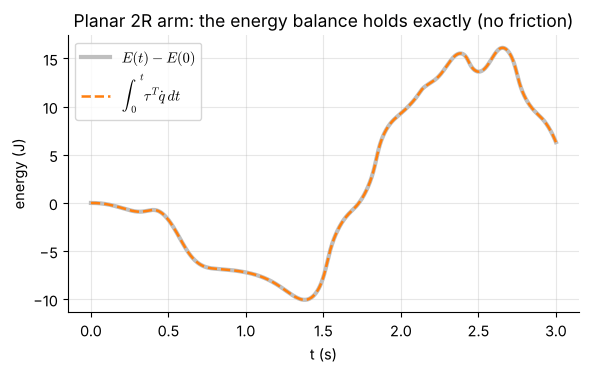

max |ΔE - ∫τ·dq| over the run: 1.61e-06 J   (peak of ΔE: 16.1 J)


with viscous friction: ΔE = -26.0583 J,   ∫τ·dq − ∫ b qd² dt = -26.0583 J


In [9]:
arm = mbc.Planar2R.from_links(m1=3.0, m2=2.0, l1=0.5, l2=0.5)       # uniform rods; masses 3 kg, 2 kg; lengths 0.5 m
tau_fun = lambda t, q, qd: np.array([3.0 * np.sin(3.0 * t), -1.5 * np.cos(2.0 * t)])
sim = mbc.simulate(arm, tau_fun, q0=[0.2, 0.6], T=3.0, dt=1e-3)
E = np.array([arm.energy(q, v) for q, v in zip(sim.q, sim.qd)])
W = np.concatenate([[0.0], np.cumsum(np.sum(sim.tau[:-1] * np.diff(sim.q, axis=0), axis=1))])   # ∫ tau·dq (tau is constant per step)
fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.plot(sim.t, E - E[0], lw=3, color="0.75", label=r"$E(t)-E(0)$")
ax.plot(sim.t, W, "--", color="tab:orange", lw=1.8, label=r"$\int_0^t\tau^T\dot q\,dt$")
ax.set_xlabel("t (s)"); ax.set_ylabel("energy (J)"); ax.legend(); ax.set_title("Planar 2R arm: the energy balance holds exactly (no friction)")
plt.show()
print("max |ΔE - ∫τ·dq| over the run: %.2e J   (peak of ΔE: %.1f J)" % (np.max(np.abs(E - E[0] - W)), np.max(np.abs(E - E[0]))))
# the same arm, now with viscous friction: E decreases by the dissipated energy  ∫ b·qd² dt
fr = arm.copy(viscous=(0.8, 0.5))
sim_f = mbc.simulate(fr, tau_fun, q0=[0.2, 0.6], T=3.0, dt=1e-3)
E_f = np.array([fr.energy(q, v) for q, v in zip(sim_f.q, sim_f.qd)])
W_f = np.sum(sim_f.tau[:-1] * np.diff(sim_f.q, axis=0))
D_f = trap(np.sum(fr.viscous * sim_f.qd**2, axis=1), sim_f.t)
print("with viscous friction: ΔE = %.4f J,   ∫τ·dq − ∫ b qd² dt = %.4f J" % (E_f[-1] - E_f[0], W_f - D_f))

## 10. A real robot: the power balance of a UR5e in MuJoCo

Does the identity $\dot E=\tau^{\mathsf T}\dot q$ hold for the full six-joint UR5e of
[MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie), with its meshes, offset joints and
rotor inertia? MuJoCo can report the total energy of a model if the flag `mjENBL_ENERGY` is on: `data.energy[0]`
is the potential energy (gravity and springs) and `data.energy[1]` the kinetic energy $\tfrac12\dot q^{\mathsf T}M\dot q$, with $M$
including the joint **armature**. We apply a smooth torque through `data.qfrc_applied` and compare $E(T)-E(0)$ with
$\int\tau^{\mathsf T}\dot q\,dt$.

**Which MuJoCo flags are active?** We are explicit, because they decide whether the identity can hold:

* gravity: **on** ($g=9.81$ m/s² along $-z$, the model default);
* built-in position actuators: **switched off** (`mjDSBL_ACTUATION`), so only our `qfrc_applied` acts;
* contacts: **switched off** (`mjDSBL_CONTACT`) — the arm does not touch anything, and the floor of the display scene must not interfere;
* joint limits and joint friction: the UR5e model has wide limits (never reached below) and `frictionloss = 0`, `damping = 0`; **armature** $=0.1$ kg m² on every joint (part of $M$);
* energy computation: **on** (`mjENBL_ENERGY`).

The integrator matters: MuJoCo's default for this model is `implicitfast` (a semi-implicit Euler-like scheme
that is cheap and robust but *not energy-exact*). We therefore repeat the experiment with the fourth-order
Runge–Kutta integrator `RK4`.

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)


flags: {'timestep': 0.002, 'integrator': 'RK4', 'gravity': (np.float64(0.0), np.float64(0.0), np.float64(-9.81)), 'disabled': ['CONTACT', 'ACTUATION'], 'enabled': ['ENERGY'], 'dof_damping': (np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)), 'dof_armature': (np.float64(0.1), np.float64(0.1), np.float64(0.1), np.float64(0.1), np.float64(0.1), np.float64(0.1)), 'dof_frictionloss': (np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)), 'n_actuators': 6}
MuJoCo kinetic energy equals 1/2 qd' M qd (M includes the armature): True


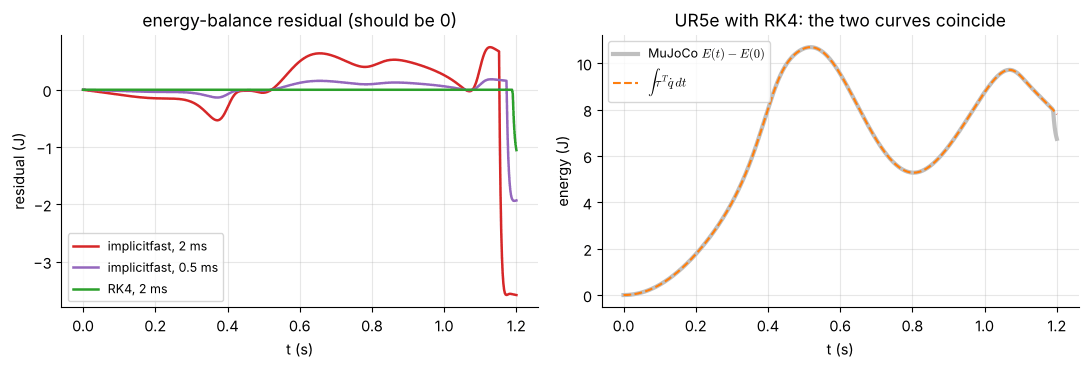

implicitfast, 2 ms    : ΔE =   3.7702 J, ∫τ·dq =   7.3547 J, residual = -3.58e+00 J, largest joint excursion 1.58 rad
implicitfast, 0.5 ms  : ΔE =   5.7552 J, ∫τ·dq =   7.6875 J, residual = -1.93e+00 J, largest joint excursion 1.59 rad
RK4, 2 ms             : ΔE =   6.7393 J, ∫τ·dq =   7.7922 J, residual = -1.05e+00 J, largest joint excursion 1.58 rad


In [10]:
import mujoco
from rgkit import robots
print(robots.describe("ur5e"))

q_start = np.array([0.0, -np.pi / 4, np.pi / 2, -np.pi / 4, -np.pi / 2, 0.0])
def energy_balance(integrator, timestep, T=1.2):
    model, data = robots.load_robot("ur5e")
    model.opt.integrator, model.opt.timestep = integrator, timestep
    mbc.configure_torque_control(model, contacts=False, energy=True)
    data.qpos[:], data.qvel[:] = q_start, 0.0
    mujoco.mj_forward(model, data)
    Etot = lambda: data.energy[0] + data.energy[1]
    E0, ts, Es, Ws, W = Etot(), [0.0], [0.0], [0.0], 0.0
    for k in range(int(round(T / timestep))):
        tau = 4.0 * np.sin(2 * np.pi * 0.8 * data.time + np.arange(6)) * np.array([1, 1, 1, 0.1, 0.1, 0.1])
        data.qfrc_applied[:] = tau
        q_before = data.qpos.copy()
        mujoco.mj_step(model, data)
        W += tau @ (data.qpos - q_before)             # torque is constant over the step: work = tau . dq
        mujoco.mj_forward(model, data)                # refresh energies at the new state
        ts.append(data.time); Es.append(Etot() - E0); Ws.append(W)
    qmax = np.abs(data.qpos - q_start).max()
    return np.array(ts), np.array(Es), np.array(Ws), model, data, qmax

runs = {}
for name, integ, dt in [("implicitfast, 2 ms", mujoco.mjtIntegrator.mjINT_IMPLICITFAST, 2e-3),
                        ("implicitfast, 0.5 ms", mujoco.mjtIntegrator.mjINT_IMPLICITFAST, 5e-4),
                        ("RK4, 2 ms", mujoco.mjtIntegrator.mjINT_RK4, 2e-3)]:
    runs[name] = energy_balance(integ, dt)

model_ur, data_ur = runs["RK4, 2 ms"][3], runs["RK4, 2 ms"][4]
M_ur = mbc.mass_matrix(model_ur, data_ur)
print("flags:", mbc.describe_flags(model_ur))
print("MuJoCo kinetic energy equals 1/2 qd' M qd (M includes the armature):",
      np.isclose(data_ur.energy[1], 0.5 * data_ur.qvel @ M_ur @ data_ur.qvel))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, (ts, Es, Ws, *_)), col in zip(runs.items(), ["tab:red", "tab:purple", "tab:green"]):
    axes[0].plot(ts, Es - Ws, color=col, lw=1.8, label=name)
axes[0].set_xlabel("t (s)"); axes[0].set_ylabel("residual (J)"); axes[0].legend(fontsize=9)
axes[0].set_title("energy-balance residual (should be 0)")
ts, Es, Ws, *_ = runs["RK4, 2 ms"]
axes[1].plot(ts, Es, lw=3, color="0.75", label=r"MuJoCo $E(t)-E(0)$"); axes[1].plot(ts, Ws, "--", color="tab:orange", label=r"$\int\tau^T\dot q\,dt$")
axes[1].set_xlabel("t (s)"); axes[1].set_ylabel("energy (J)"); axes[1].legend(fontsize=9); axes[1].set_title("UR5e with RK4: the two curves coincide")
plt.tight_layout(); plt.show()
for name, (ts, Es, Ws, m_, d_, qmax) in runs.items():
    print(f"{name:22s}: ΔE = {Es[-1]:8.4f} J, ∫τ·dq = {Ws[-1]:8.4f} J, residual = {Es[-1]-Ws[-1]:+.2e} J, largest joint excursion {qmax:.2f} rad")

With the RK4 integrator the energy balance holds to about $10^{-5}$ J, i.e. to the accuracy of the
integration: **a six-joint robot with real link inertias is passive from joint torque to joint velocity**, exactly
as the derivation says. With `implicitfast` the residual is much larger and shrinks with the time step. This is not a flaw
of the physics but of the numerical integrator — a warning to keep in mind later: the Lyapunov proofs of
this chapter are statements about the continuous-time system, and a discrete-time implementation (a
simulator's integrator, a digital controller) preserves them only approximately (Section 3.4 quantifies this for the controller).

(The residual is not caused by joint limits: an active limit would absorb energy and spoil the RK4 balance, which holds to
better than $10^{-5}$ J.)

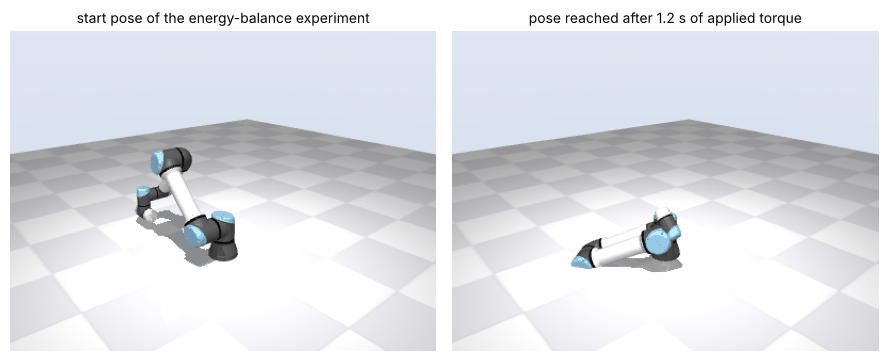

In [11]:
try:
    from rgkit import mujoco_utils as mju
    model, data = robots.load_robot("ur5e")
    cam = dict(azimuth=140, elevation=-20, distance=1.9, lookat=(0, 0, 0.35))
    data.qpos[:] = q_start; mujoco.mj_forward(model, data)
    img1 = mju.render(model, data, camera=cam, width=400, height=300)
    data.qpos[:] = runs["RK4, 2 ms"][4].qpos; mujoco.mj_forward(model, data)       # final pose of the RK4 run
    img2 = mju.render(model, data, camera=cam, width=400, height=300)
    filmstrip([img1, img2], ["start pose of the energy-balance experiment", "pose reached after 1.2 s of applied torque"], width=9)
except Exception as exc:                                    # rendering is optional
    print("rendering skipped:", type(exc).__name__, exc)

## 11. Worked examples

**Example 3.1.1 — $\dot x=\mp x^3$.** Show with $V=x^2$ that the origin of $\dot x=-x^3$ is asymptotically (globally, but not exponentially)
stable and that of $\dot x=+x^3$ is unstable.

*Solution.* $V=x^2$ is positive definite and radially unbounded, and $\dot V=2x\dot x=\mp2x^4$. For $\dot x=-x^3$,
$\dot V=-2x^4<0$ for $x\ne0$: globally asymptotically stable by part 3 of Lyapunov's theorem. The solution
$x(t)=x_0/\sqrt{1+2x_0^2t}$ decays like $t^{-1/2}$, slower than any exponential, so the stability is not exponential — which also
explains why the linearisation ($\dot z=0$) could not see it. For $\dot x=+x^3$, $\dot V=+2x^4>0$ and a trajectory started at $x_0=1$
escapes to infinity at $t=1/(2x_0^2)=0.5$.

**Example 3.1.2 — a Lyapunov equation by hand.** Solve $A^{\mathsf T}P+PA=-I$ for $A=\begin{bmatrix}0&1\\-2&-3\end{bmatrix}$ and
find the certified decay rate $\rho$.

*Solution.* Let $P=\begin{bmatrix}p_1&p_2\\p_2&p_3\end{bmatrix}$. Expanding gives $-4p_2=-1$, $p_1-3p_2-2p_3=0$, $2p_2-6p_3=-1$, so
$p_2=\tfrac14$, $p_3=\tfrac14$, $p_1=\tfrac54$. The eigenvalues of $P$ are $0.191$ and $1.309$, hence $\rho=1/1.309=0.764$.
(True poles: $-1$ and $-2$, so $V$ actually decays at rate $2$; the certificate is safe but conservative.)

**Example 3.1.3 — an exact region of attraction.** For $\dot x=-x+x^3$ take $V=x^2$. Then $\dot V=-2x^2(1-x^2)$, negative for $0<|x|<1$, so
$\{|x|<1\}$ is a region of attraction. It is exact, since $x=\pm1$ are the other equilibria.

**Example 3.1.4 — energy dissipated by the damper.** The pendulum with $b=0.4$ is released from rest at $\theta_0=2.5$ rad. By
$\dot E=-b\omega^2$ the energy lost between $t=0$ and $T$ equals $b\int_0^T\omega^2dt$. The initial energy is
$1-\cos2.5$. Check by quadrature that the energy lost up to $T=60$ equals the initial energy.

**Example 3.1.5 — passivity of a mass–spring–damper.** For $m\ddot x+c\dot x+kx=F$ with $m=2$ kg, $c=3$ N s/m, $k=50$ N/m, $S=\tfrac12m\dot x^2+\tfrac12kx^2$
gives $\dot S=F\dot x-c\dot x^2$. For $F(t)=10\sin(2t)$, starting at rest, check numerically that $\int_0^{5}F\dot x\,dt = S(5)+c\int_0^5\dot x^2dt$.

In [12]:
# Example 3.1.1
x0 = 1.0
tr = ly.rk4_trajectory(lambda x: -x**3, [x0], np.linspace(0, 10, 20001))
print("3.1.1: x(10) =", tr[-1, 0].round(4), "closed form", (x0 / np.sqrt(1 + 2 * x0**2 * 10)).round(4), "| escape time of +x^3 from x0=1:", 1 / (2 * x0**2))
assert abs(tr[-1, 0] - 1 / np.sqrt(21)) < 1e-6

# Example 3.1.2
A2 = np.array([[0.0, 1.0], [-2.0, -3.0]])
P2 = ly.solve_lyapunov(A2)
lam = np.linalg.eigvalsh(P2)
print("3.1.2: P =", P2.round(4).tolist(), " eig(P) =", lam.round(3), " rho =", round(1 / lam.max(), 3), " poles:", np.linalg.eigvals(A2))
assert np.allclose(P2, [[1.25, 0.25], [0.25, 0.25]]) and abs(1 / lam.max() - 0.764) < 1e-3

# Example 3.1.3
xs = np.linspace(-2, 2, 4001)
Vd = -2 * xs**2 * (1 - xs**2)
print("3.1.3: Vdot < 0 for 0<|x|<1 and >= 0 for |x|>=1 on the grid:", bool(np.all(Vd[(np.abs(xs) < 1) & (xs != 0)] < 0) and np.all(Vd[np.abs(xs) >= 1] >= 0)))

# Example 3.1.4
tt = np.linspace(0, 60, 60001)
tr = ly.rk4_trajectory(ly.pendulum_field(1.0, 0.4), [2.5, 0.0], tt)
lost = 0.4 * trap(tr[:, 1] ** 2, tt)
print("3.1.4: E(0) = %.4f, energy dissipated by the damper over 60 s = %.4f" % (1 - np.cos(2.5), lost))
assert abs(lost - (1 - np.cos(2.5))) < 1e-3

# Example 3.1.5
m_, c_, k_ = 2.0, 3.0, 50.0
msd = lambda x: np.array([x[1], (10 * np.sin(2 * x[2]) - c_ * x[1] - k_ * x[0]) / m_, 1.0])
tt = np.linspace(0, 5, 50001)
s = ly.rk4_trajectory(msd, [0, 0, 0], tt)
power_in = 10 * np.sin(2 * s[:, 2]) * s[:, 1]
work_in = trap(power_in, tt); stored = 0.5 * m_ * s[-1, 1] ** 2 + 0.5 * k_ * s[-1, 0] ** 2; dissipated = c_ * trap(s[:, 1] ** 2, tt)
print("3.1.5: ∫F v dt = %.4f J,  S(5) = %.4f J,  c∫v² dt = %.4f J,  S + dissipated = %.4f J" % (work_in, stored, dissipated, stored + dissipated))
assert abs(work_in - stored - dissipated) < 1e-6

3.1.1: x(10) = 0.2182 closed form 0.2182 | escape time of +x^3 from x0=1: 0.5
3.1.2: P = [[1.25, 0.25], [0.25, 0.25]]  eig(P) = [0.191 1.309]  rho = 0.764  poles: [-1.+0.j -2.+0.j]
3.1.3: Vdot < 0 for 0<|x|<1 and >= 0 for |x|>=1 on the grid: True


3.1.4: E(0) = 1.8011, energy dissipated by the damper over 60 s = 1.8011


3.1.5: ∫F v dt = 2.3102 J,  S(5) = 0.4281 J,  c∫v² dt = 1.8821 J,  S + dissipated = 2.3102 J


## 12. Summary

| Concept | Statement |
|:--|:--|
| Equilibrium | $f(x^\ast)=0$; shift it to the origin |
| Stable / asymptotically stable | trajectories stay near / and converge; global if for every initial state |
| Indirect method | Jacobian eigenvalues all in the open left half-plane $\Rightarrow$ exponentially stable; one with positive real part $\Rightarrow$ unstable; imaginary-axis eigenvalues $\Rightarrow$ **inconclusive** |
| Direct method | $V>0$, $\dot V\le0$ $\Rightarrow$ stable; $\dot V<0$ $\Rightarrow$ asymptotically stable; plus radially unbounded $\Rightarrow$ global |
| Lyapunov equation | $A^{\mathsf T}P+PA=-Q$; solvable with $P>0$ iff $A$ Hurwitz; rate $\rho=\lambda_{\min}(Q)/\lambda_{\max}(P)$ |
| Region of attraction | largest sublevel set $\{V<c^\ast\}$ on which $\dot V<0$; conservative |
| LaSalle | $\dot V\le0$ on a compact invariant set $\Rightarrow$ convergence to the largest invariant set in $\{\dot V=0\}$ |
| Passivity | $\dot S\le u^{\mathsf T}y$; manipulator: $u=\tau$, $y=\dot q$, $S=E-U_{\min}$, $\dot E=\tau^{\mathsf T}\dot q$ (skew-symmetry of $\dot M-2C$) |

### Common mistakes

* Concluding **asymptotic** stability from $\dot V\le0$ alone. Negative *semi*-definiteness gives stability only; add LaSalle (or find a better $V$).
* Applying LaSalle without checking the **invariance**: it is not enough that $\dot V=0$ at a point — the whole solution must remain where $\dot V=0$.
* Treating a failed candidate as a proof of instability. The Lyapunov conditions are sufficient only.
* Forgetting radial unboundedness when claiming a *global* result: $E$ of the pendulum is not radially unbounded in $\theta$ (and the pendulum has many equilibria), so no global result is possible.
* Trusting the indirect method when the Jacobian has eigenvalues on the imaginary axis (undamped systems, systems with integrators).
* Mixing up $\dot V(x)=\nabla V\cdot f(x)$ with the derivative of $V(x(t))$ **computed from a simulation** — they agree, but the first needs no simulation.

## Exercises

**3.1.1** Show that the origin of $\dot x_1=-x_1+x_2^2$, $\dot x_2=-x_2$ is asymptotically stable. Use $V=x_1^2+x_2^2$ to find the largest disc that this function certifies as a region of attraction, and then use the exact solution to show that the stability is in fact global.

<details><summary>Answer</summary>

$\dot V=-2x_1^2+2x_1x_2^2-2x_2^2=-2x_1^2-2x_2^2\,(1-x_1)$, which is negative except possibly where $x_1>1$ and $x_2^2\ge x_1^2/(x_1-1)$. The smallest value of $V$ on that curve is $x_1^3/(x_1-1)$, minimised at $x_1=\tfrac32$, where it equals $\tfrac{27}{4}=6.75$. So $\{x_1^2+x_2^2<6.75\}$ is a certified region of attraction (the grid estimate printed by the check cell agrees up to the grid resolution). Globally: $x_2(t)=x_2(0)e^{-t}$ and then $x_1(t)=\big(x_1(0)+x_2(0)^2\big)e^{-t}-x_2(0)^2e^{-2t}$, which tends to $0$ for every initial state, so the origin is <b>globally</b> (and exponentially) asymptotically stable — the quadratic $V$ is simply too conservative.
</details>

**3.1.2** For $\dot x_1=x_2$, $\dot x_2=-x_1^3-x_2$ show that the linearisation is inconclusive and prove global asymptotic stability using $V=\tfrac14x_1^4+\tfrac12x_2^2$ and LaSalle's principle.

<details><summary>Answer</summary>

$A=\begin{bmatrix}0&1\\0&-1\end{bmatrix}$ has eigenvalues $0,-1$: inconclusive. $V$ is positive definite and radially unbounded; $\dot V=x_1^3x_2+x_2(-x_1^3-x_2)=-x_2^2\le0$. On $\{\dot V=0\}=\{x_2=0\}$ a solution that stays must have $\dot x_2=-x_1^3=0$, so $x_1=0$: the largest invariant set is $\{0\}$. By LaSalle the origin is globally asymptotically stable. (Convergence is slow, algebraic: see the numerical check.)
</details>

**3.1.3** Solve $A^{\mathsf T}P+PA=-I$ for $A=\begin{bmatrix}-1&1\\0&-2\end{bmatrix}$. Give $\rho$ and verify that $V=x^{\mathsf T}Px$ is a Lyapunov function.

<details><summary>Answer</summary>

Writing the three scalar equations: $-2p_1=-1$, $p_1-3p_2=0$, $2(p_2-2p_3)=-1$, so $P=\begin{bmatrix}1/2&1/6\\1/6&1/3\end{bmatrix}$. Its eigenvalues are $0.2303$ and $0.6030$ (both positive, so $V$ is positive definite), hence $\rho=1/0.6030=1.658$ and $V(x(t))\le V(x(0))e^{-1.658t}$ (the true rate of $V$ is $2\cdot1=2$). $\dot V=-x^{\mathsf T}x<0$.
</details>

**3.1.4** Show that the map from the torque $\tau$ applied to a single pendulum link $J\ddot q+mg\ell\sin q=\tau$ (a link of inertia $J$ about the joint) to $\dot q$ is passive and find the storage function. Check numerically with $J=0.5$, $mg\ell=4$, $\tau(t)=3\sin t$, $q(0)=0.3$, $\dot q(0)=0$ for $0\le t\le 6$.

<details><summary>Answer</summary>

$S=\tfrac12J\dot q^2+mg\ell(1-\cos q)\ge0$ gives $\dot S=\dot q(J\ddot q+mg\ell\sin q)=\tau\dot q$. Hence $\int_0^6\tau\dot q\,dt=S(6)-S(0)$; the numbers are printed in the check cell.
</details>

**3.1.5** (*MuJoCo*) With RK4 at 2 ms and the flags of Section 10, apply a constant torque of 20 N m to the shoulder-pan joint (joint 1) of the UR5e at the start pose of Section 10, with all other joints unactuated (free). Report $\Delta E$ and $\int\tau\dot q_1\,dt$ for 0.4 s.

<details><summary>Answer</summary>

Only joint 1 receives external work, so $\dot E=\tau_1\dot q_1$ even though the other joints move (they exchange energy with joint 1 through $M$ and $C$, and with gravity through $U$). The two numbers agree to better than $10^{-3}$ J; the values are printed by the check cell below.
</details>

**3.1.6** (*Programming*) For $\ddot x+\dot x+x-x^3=0$ (a "soft" spring, equilibria $0,\pm1$) use $V=\tfrac12\dot x^2+\tfrac12x^2-\tfrac14x^4$ and LaSalle to find a region of attraction, and compare with a grid simulation.

<details><summary>Answer</summary>

$\dot V=-\dot x^2\le0$. $V$ is positive definite near the origin; the saddle points $(\pm1,0)$ have $V=\tfrac14$. The connected component of $\{V<\tfrac14\}$ containing the origin (the region where $|x|<1$) is compact and invariant, and LaSalle (largest invariant set in $\{\dot x=0\}$ is the origin because $\dot x\equiv0\Rightarrow x-x^3=0$) shows it lies in the region of attraction. The grid simulation (check cell) confirms that every starting point inside converges to the origin.
</details>

**3.1.7** Explain in two or three sentences why the energy $E$ of the pendulum cannot be used to prove *global* asymptotic stability of the hanging position, however much damping is added.

<details><summary>Answer</summary>

Global asymptotic stability would require every trajectory to converge to the hanging position, but the upright position $(\pi,0)$ is also an equilibrium (a trajectory placed exactly there never leaves). Moreover $E$ is bounded in the $\theta$ direction ($E\le 2$ on the line $\omega=0$) and therefore not radially unbounded. At best one proves convergence to the *set* of equilibria, or asymptotic stability with a region of attraction $\{E<2\}$.
</details>

In [13]:
# ----- numerical checks of the exercise answers -----
# 3.1.1 grid estimate of the region of attraction with V = x1^2 + x2^2
X1, X2 = np.meshgrid(np.linspace(-3, 3, 601), np.linspace(-3, 3, 601))
Vg1, Vd1 = ly.vdot_on_grid(lambda x, y: (-x + y**2, -y), lambda x, y: x**2 + y**2, lambda x, y: (2 * x, 2 * y), X1, X2)
print("3.1.1 c* =", round(ly.level_set_estimate(Vg1, Vd1, X1, X2), 3))
end = ly.rk4_batch(lambda X: np.stack([-X[:, 0] + X[:, 1] ** 2, -X[:, 1]], -1), np.random.default_rng(0).uniform(-5, 5, (200, 2)), 30.0, 3000)
print("      random starts in [-5,5]^2 all converge:", bool(np.all(np.linalg.norm(end, axis=1) < 1e-6)))

# 3.1.2 energy decay of xdot2 = -x1^3 - x2
f312 = lambda x: np.array([x[1], -x[0] ** 3 - x[1]])
tr = ly.rk4_trajectory(f312, [2.0, 0.0], np.linspace(0, 200, 40001))
V312 = 0.25 * tr[:, 0] ** 4 + 0.5 * tr[:, 1] ** 2
print("3.1.2 V non-increasing:", bool(np.all(np.diff(V312) <= 1e-12)), "  V(0)=%.3f  V(200)=%.2e  |x(200)|=%.3f (algebraic decay)" % (V312[0], V312[-1], np.linalg.norm(tr[-1])))

# 3.1.3
A3 = np.array([[-1.0, 1.0], [0.0, -2.0]]); P3 = ly.solve_lyapunov(A3)
print("3.1.3 P =", P3.round(4).tolist(), " eig(P) =", np.linalg.eigvalsh(P3).round(4), " rho =", round(1 / np.linalg.eigvalsh(P3).max(), 4), " P>0:", ly.is_positive_definite(P3))

# 3.1.4 pendulum link
J, mgl = 0.5, 4.0
tt = np.linspace(0, 6, 60001)
f314 = lambda x: np.array([x[1], (3 * np.sin(x[2]) - mgl * np.sin(x[0])) / J, 1.0])
s = ly.rk4_trajectory(f314, [0.3, 0.0, 0.0], tt)
S = lambda x: 0.5 * J * x[:, 1] ** 2 + mgl * (1 - np.cos(x[:, 0]))
work = trap(3 * np.sin(tt) * s[:, 1], tt)
print("3.1.4 ∫τ q̇ dt = %.4f J,  S(6)-S(0) = %.4f J" % (work, S(s)[-1] - S(s)[0]))
assert abs(work - (S(s)[-1] - S(s)[0])) < 1e-5

# 3.1.5 UR5e, constant torque on joint 1 only
model, data = robots.load_robot("ur5e")
model.opt.integrator, model.opt.timestep = mujoco.mjtIntegrator.mjINT_RK4, 2e-3
mbc.configure_torque_control(model, energy=True)
data.qpos[:] = q_start; mujoco.mj_forward(model, data)
E0, W = data.energy.sum(), 0.0
for _ in range(200):
    data.qfrc_applied[:] = [20.0, 0, 0, 0, 0, 0]
    qb = data.qpos[0]; mujoco.mj_step(model, data); W += 20.0 * (data.qpos[0] - qb)
mujoco.mj_forward(model, data)
print("3.1.5 ΔE = %.5f J,  ∫τ q̇1 dt = %.5f J,  q1 moved %.3f rad in 0.4 s" % (data.energy.sum() - E0, W, data.qpos[0] - q_start[0]))
assert abs(data.energy.sum() - E0 - W) < 1e-3

# 3.1.6 soft spring: grid simulation of the region of attraction
x1, x2 = np.meshgrid(np.linspace(-1.6, 1.6, 120), np.linspace(-1.6, 1.6, 120))
fsoft = lambda X: np.stack([X[:, 1], -X[:, 1] - X[:, 0] + X[:, 0] ** 3], -1)
with np.errstate(all="ignore"):
    XT = ly.rk4_batch(fsoft, np.stack([x1.ravel(), x2.ravel()], -1), 80.0, 4000)
conv = (np.linalg.norm(XT, axis=1) < 1e-3).reshape(x1.shape)
Vs = 0.5 * x2**2 + 0.5 * x1**2 - 0.25 * x1**4
inside = (Vs < 0.25) & (np.abs(x1) < 1)
print("3.1.6 every grid point in {V<1/4, |x|<1} converges to 0:", bool(conv[inside].all()), "; fraction of all grid points that converge: %.2f" % conv.mean())

3.1.1 c* = 6.757
      random starts in [-5,5]^2 all converge: True


3.1.2 V non-increasing: True   V(0)=4.000  V(200)=1.42e-06  |x(200)|=0.049 (algebraic decay)
3.1.3 P = [[0.5, 0.1667], [0.1667, 0.3333]]  eig(P) = [0.2303 0.603 ]  rho = 1.6584  P>0: True


3.1.4 ∫τ q̇ dt = 0.7840 J,  S(6)-S(0) = 0.7840 J
3.1.5 ΔE = 14.25398 J,  ∫τ q̇1 dt = 14.25398 J,  q1 moved 0.713 rad in 0.4 s


3.1.6 every grid point in {V<1/4, |x|<1} converges to 0: True ; fraction of all grid points that converge: 0.57


## Further reading and lectures

* Craig, 3rd ed., Ch. 10 (the section on Lyapunov stability analysis of the manipulator control law).
* Slotine & Li, *Applied Nonlinear Control*, Ch. 3 (definitions, direct method, invariant-set theorems) and Ch. 4 (positive real and passivity ideas, Barbalat's lemma).
* Khalil, *Nonlinear Systems*, 3rd ed., Ch. 4 (Lyapunov stability, LaSalle) and the chapters on passivity and feedback systems.
* Spong, Hutchinson & Vidyasagar, *Robot Modeling and Control*, 2nd ed., Appendix C (Lyapunov stability).
* R. Tedrake, *Underactuated Robotics* (free online notes, <https://underactuated.mit.edu/>): the simple pendulum and Lyapunov analysis.
* Video: [Sapienza *Robotics 2* (A. De Luca), lecture playlist](https://www.youtube.com/playlist?list=PLAQopGWlIcya6LnIF83QlJTqvpYmJXnDm); Prof. G. C. Nandi, *Mathematical Foundation of Robotics — Execution Level …* (second playlist; URL not yet verified).
* MuJoCo documentation on [energy computation and the `energy` flag](https://mujoco.readthedocs.io/en/stable/APIreference/APItypes.html).

---

[Chapter contents](README.md) &nbsp;·&nbsp; 3.2 PD Control with Gravity Compensation → *(planned)*